In [1]:
from pathlib import Path
from matplotlib.figure import Figure

OUTPUT_DIR = Path('output')
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Evita encadenar wrappers si esta celda se ejecuta varias veces.
if not hasattr(Figure, '_copilot_original_savefig'):
    Figure._copilot_original_savefig = Figure.savefig

    def _savefig_to_output(self, fname, *args, **kwargs):
        if isinstance(fname, (str, Path)):
            path_obj = Path(fname)
            if path_obj.parent == Path('.'):
                fname = OUTPUT_DIR / path_obj.name
        return Figure._copilot_original_savefig(self, fname, *args, **kwargs)

    Figure.savefig = _savefig_to_output

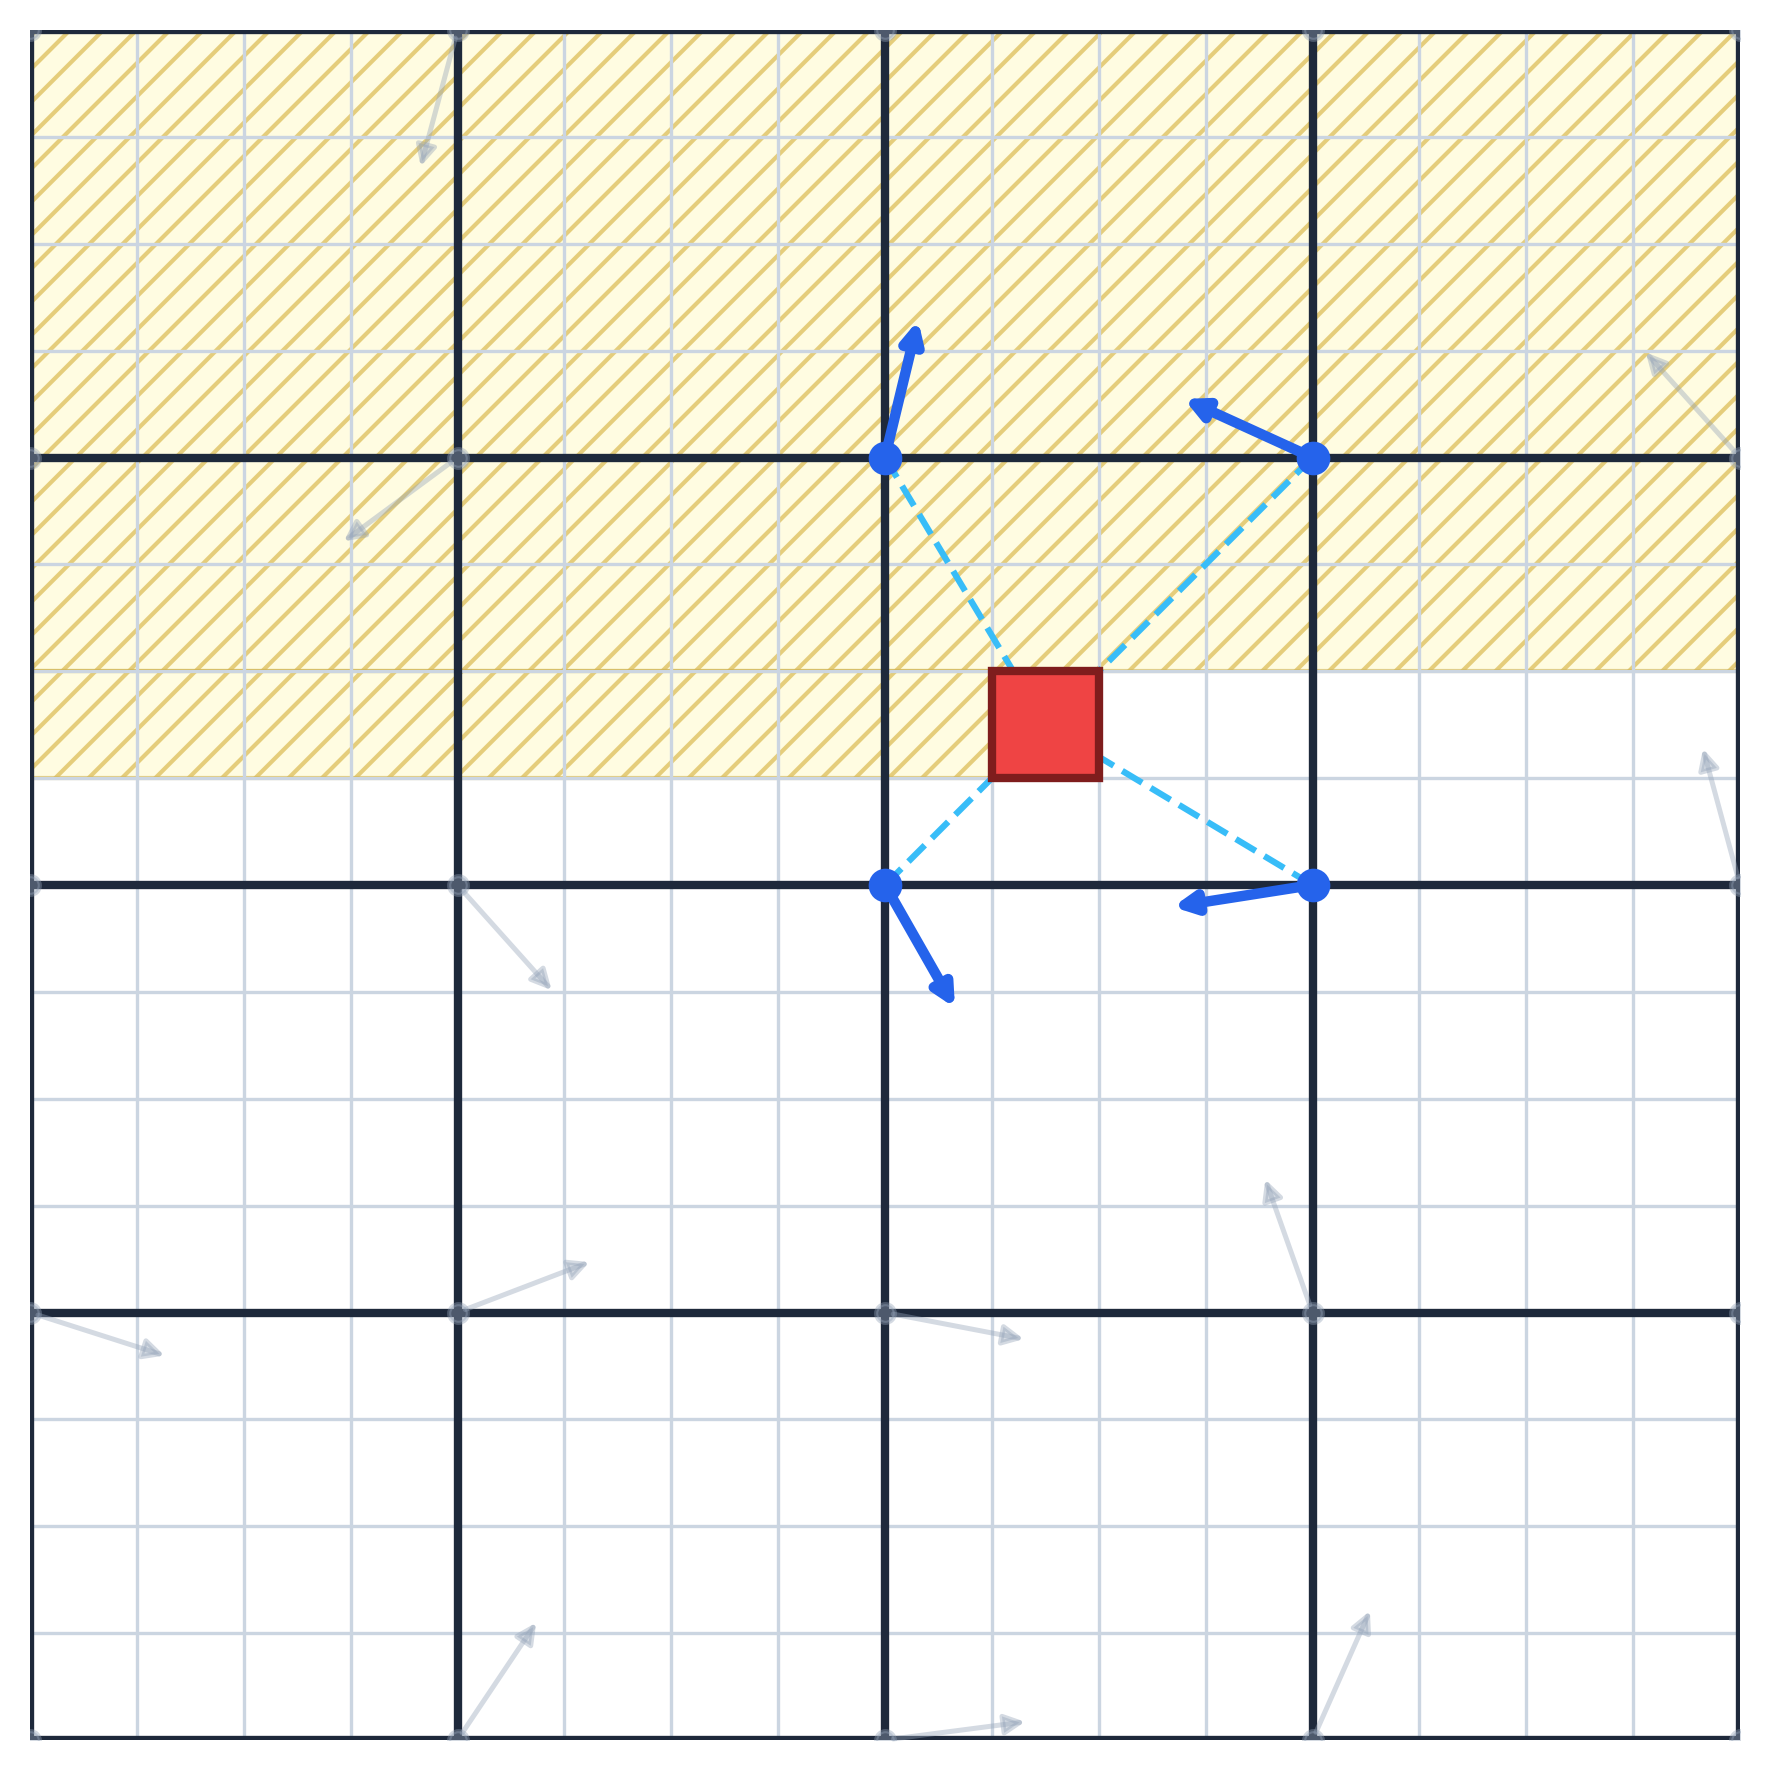

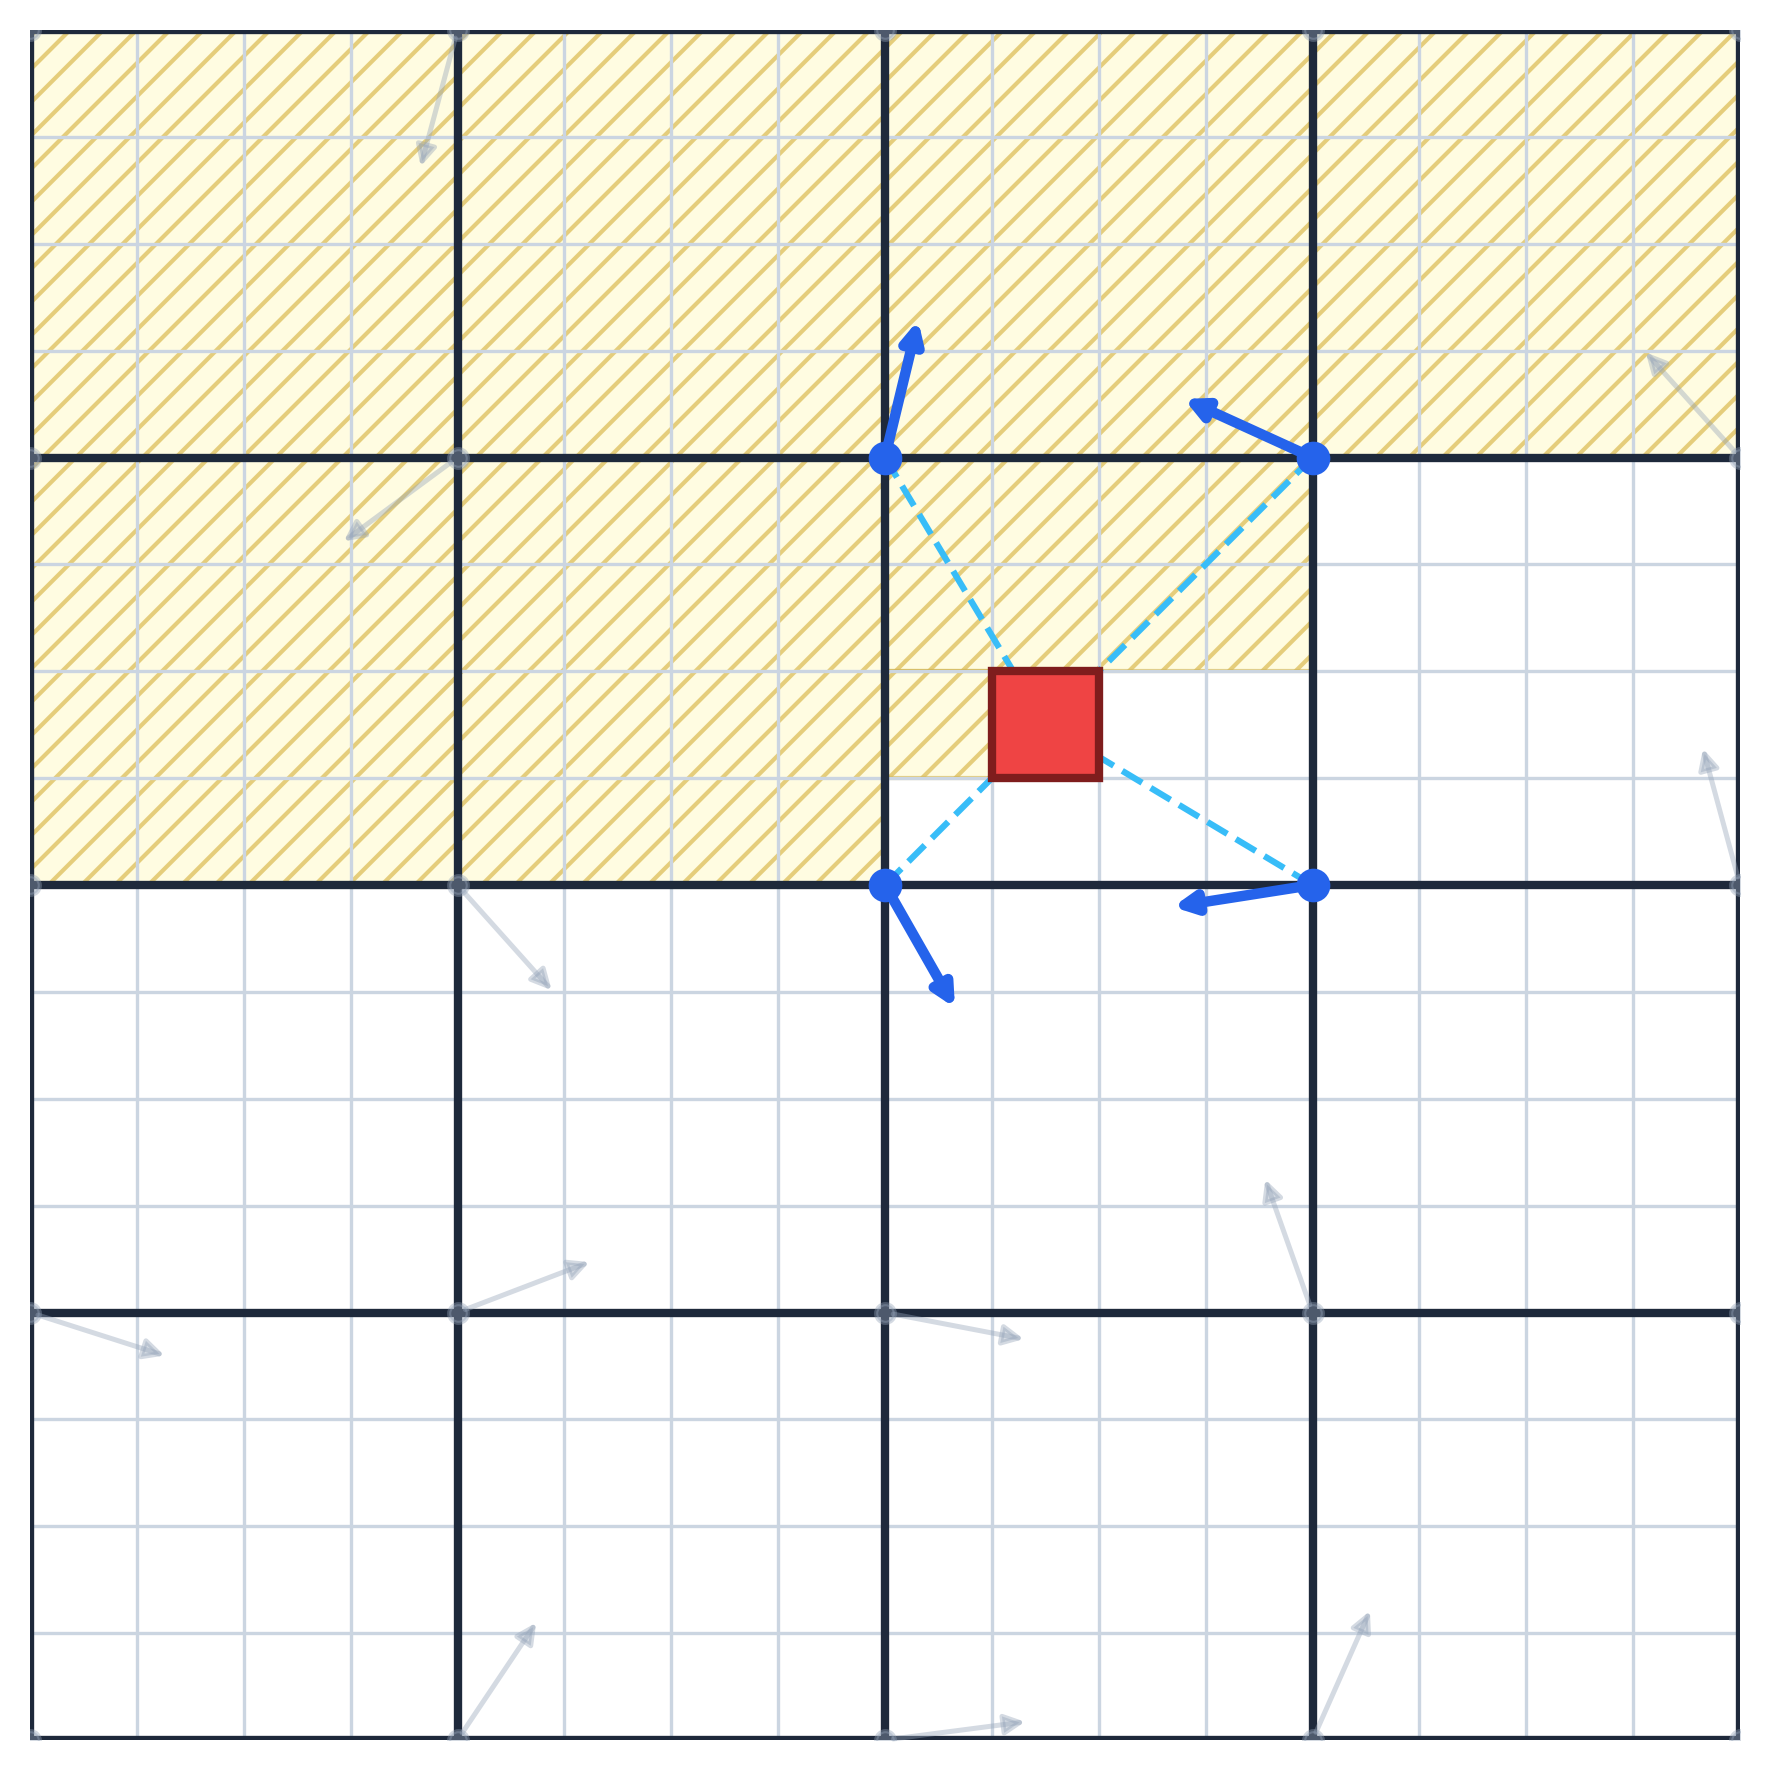

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import numpy as np

# ==========================================
# --- CONFIGURACIÓN COMPARTIDA ---
# ==========================================
COLOR_LAVANDA = '#E6E6FA'
COLOR_AMARILLO_PASTEL = '#FFFACD'
COLOR_ROJO_PASTEL = '#FFCCCC'
COLOR_VERDE_PASTEL = '#F0FFF0'
COLOR_BORDE_OSCURO = '#333333'
COLOR_TEXTO_SECUNDARIO = '#555555'
COLOR_TEXTO_BAJO = '#444444'
COLOR_ROJO_ACENTO = '#D32F2F'
COLOR_ROJO_VIVO = '#EF4444'
COLOR_AZUL_ACENTO = '#2563EB'
COLOR_AZUL_SUAVE = '#94A3B8'
COLOR_AZUL_CLARO = '#38BDF8'
COLOR_DORADO = '#D4AF37'
COLOR_BORDE_ACTIVO = '#7F1D1D'
COLOR_GRIS_CLARO = '#AAAAAA'
COLOR_GRIS_MUY_CLARO = '#F9F9F9'
COLOR_BLANCO = '#FFFFFF'
COLOR_GRILLA_FINA = '#cbd5e1'
COLOR_GRILLA_PRINCIPAL = '#1e293b'

COMMON_COLORS = {
    'lavender': COLOR_LAVANDA,
    'pastel_yellow': COLOR_AMARILLO_PASTEL,
    'pastel_red': COLOR_ROJO_PASTEL,
    'pastel_green': COLOR_VERDE_PASTEL,
    'dark_border': COLOR_BORDE_OSCURO,
    'muted_text': COLOR_TEXTO_SECUNDARIO,
    'text_below': COLOR_TEXTO_BAJO,
    'accent_red': COLOR_ROJO_ACENTO,
    'accent_blue': COLOR_AZUL_ACENTO,
    'soft_blue': COLOR_AZUL_SUAVE,
    'light_gray': COLOR_GRIS_CLARO,
    'off_white': COLOR_GRIS_MUY_CLARO,
    'gold': COLOR_DORADO,
    'white': COLOR_BLANCO,
    'grid_fine': COLOR_GRILLA_FINA,
    'grid_main': COLOR_GRILLA_PRINCIPAL,
}

FONT_SIZE_TITLE_SMALL = 18
FONT_SIZE_TITLE = 20
FONT_SIZE_TITLE_LARGE = 22
FONT_SIZE_TITLE_XL = 28
FONT_SIZE_TITLE_SIMD = 32
FONT_SIZE_SUBTITLE = 14
FONT_SIZE_LABEL = 13
FONT_SIZE_CELL = 18
FONT_SIZE_CELL_MEDIUM = 16
FONT_SIZE_CELL_BOLD = 15
FONT_SIZE_LEGEND = 11
FONT_SIZE_NOTE = 12

FUENTE_TITULO_BASE = {'fontweight': 'bold', 'color': 'black'}
FUENTE_SUBTITULO_BASE = {'color': COLOR_TEXTO_SECUNDARIO}
FUENTE_ETIQUETA_BASE = {'fontweight': 'bold', 'color': COLOR_TEXTO_BAJO}
FUENTE_CELDA_BASE = {'color': 'black'}
FUENTE_CELDA_BOLD_BASE = {'fontweight': 'bold'}
FUENTE_LEYENDA_BASE = {'ha': 'center', 'va': 'top', 'color': COLOR_TEXTO_SECUNDARIO}
FUENTE_ANOTACION_BASE = {'color': COLOR_TEXTO_SECUNDARIO}

PALETA_PERLIN = {
    'cuadricula_fina': COLOR_GRILLA_FINA,
    'cuadricula_principal': COLOR_GRILLA_PRINCIPAL,
    'casilla_activa': COLOR_ROJO_VIVO,
    'borde_activa': COLOR_BORDE_ACTIVO,
    'gradiente_activo': COLOR_AZUL_ACENTO,
    'gradiente_inactivo': COLOR_AZUL_SUAVE,
    'linea_distancia': COLOR_AZUL_CLARO,
    'barrido_bg': COLOR_AMARILLO_PASTEL,
    'barrido_lineas': COLOR_DORADO,
}

PALETA_CACHE = {
    'grid': 'gray',
    'borde': COLOR_BORDE_OSCURO,
    'cache_bg': COLOR_LAVANDA,
    'pixel_bg': COLOR_ROJO_PASTEL,
    'pixel_edge': COLOR_ROJO_ACENTO,
    'arrow': COLOR_ROJO_ACENTO,
    'info_bg': COLOR_AMARILLO_PASTEL,
    'info_edge': COLOR_DORADO,
}

PALETA_SIMD = {
    'fondo_vector_x': COLOR_LAVANDA,
    'fondo_escalar_y': COLOR_AMARILLO_PASTEL,
    'fondo_operacion': COLOR_ROJO_PASTEL,
    'fondo_resultado': COLOR_VERDE_PASTEL,
    'borde_normal': COLOR_BORDE_OSCURO,
    'borde_resaltado': COLOR_AZUL_ACENTO,
    'flecha_principal': COLOR_ROJO_ACENTO,
    'flecha_special': COLOR_AZUL_ACENTO,
    'texto_titulo': 'black',
    'texto_subtitulo': COLOR_TEXTO_SECUNDARIO,
    'texto_bucle': COLOR_TEXTO_BAJO,
}

PALETA_BITS = {
    'F': COLOR_LAVANDA,
    'S': COLOR_AMARILLO_PASTEL,
    'G': COLOR_ROJO_PASTEL,
    'borde': COLOR_BORDE_OSCURO,
    'texto_bit': 'black',
    'texto_leyenda': COLOR_TEXTO_SECUNDARIO,
}

PALETA_VPMULHRSW = {
    'entrada': COLOR_LAVANDA,
    'op_interna': COLOR_ROJO_PASTEL,
    'resultado': COLOR_VERDE_PASTEL,
    'descartado': COLOR_GRIS_MUY_CLARO,
    'borde': COLOR_BORDE_OSCURO,
    'borde_resalte': COLOR_AZUL_ACENTO,
    'flecha_principal': COLOR_ROJO_ACENTO,
    'flecha_resalte': COLOR_AZUL_ACENTO,
    'texto_main': 'black',
    'texto_sub': COLOR_TEXTO_SECUNDARIO,
    'texto_descartado': COLOR_GRIS_CLARO,
}

PALETA_LICM = {
    'fondo_vector_x': COLOR_LAVANDA,
    'fondo_escalar_y': COLOR_AMARILLO_PASTEL,
    'fondo_operacion': COLOR_ROJO_PASTEL,
    'fondo_cuadricula': COLOR_BLANCO,
    'borde_normal': COLOR_BORDE_OSCURO,
    'borde_resaltado': COLOR_AZUL_ACENTO,
    'flecha_principal': COLOR_ROJO_ACENTO,
    'flecha_special': COLOR_AZUL_ACENTO,
    'texto_titulo': 'black',
    'texto_subtitulo': COLOR_TEXTO_SECUNDARIO,
    'texto_bucle': COLOR_TEXTO_BAJO,
}

def apply_common_style(extra_params=None):
    base_params = {
        'mathtext.fontset': 'cm',
        'font.family': 'serif',
    }
    if extra_params:
        base_params.update(extra_params)
    plt.rcParams.update(base_params)

# Aplicar estilo base por defecto para todas las figuras.
apply_common_style()

# ==========================================
# --- CONFIGURACIÓN AJUSTABLE ---
# ==========================================
N_BLOCKS = 4
N_FINE_PER_BLOCK = 4

# Objetivo unificado: iteración 106 (105 casillas sombreadas)
TARGET_BLOCK = (2, 2)
TARGET_FINE  = (1, 1)

# --- PRECALCULAR GRADIENTES (Perlin Noise) ---
np.random.seed(42) # Semilla fija para que ambas gráficas sean idénticas
ANGULOS = np.random.uniform(0, 2 * np.pi, (N_BLOCKS + 1, N_BLOCKS + 1))

# Paleta de colores
PALETA = {
    'cuadricula_fina': COLOR_GRILLA_FINA,
    'cuadricula_principal': COLOR_GRILLA_PRINCIPAL,
    'casilla_activa': COLOR_ROJO_VIVO,
    'borde_activa': COLOR_BORDE_ACTIVO,
    'gradiente_activo': COLOR_AZUL_ACENTO,
    'gradiente_inactivo': COLOR_AZUL_SUAVE,
    'linea_distancia': COLOR_AZUL_CLARO,
    'barrido_bg': COLOR_AMARILLO_PASTEL,
    'barrido_lineas': COLOR_DORADO,
}

# ==========================================
# --- FUNCIONES DE DIBUJO ---
# ==========================================
def draw_all_grids(ax, n_blocks, n_fine_per_block, fine_color, main_color):
    """Dibuja las líneas de la cuadrícula fina y principal."""
    cell_size = 1.0 / n_fine_per_block

    # Cuadrícula fina
    for i in range(n_blocks * n_fine_per_block):
        if i % n_fine_per_block == 0: 
            continue
        ax.axvline(i * cell_size, color=fine_color, linewidth=0.8, zorder=1)
        ax.axhline(i * cell_size, color=fine_color, linewidth=0.8, zorder=1)

    # Cuadrícula principal
    for i in range(n_blocks + 1):
        ax.axvline(i, color=main_color, linewidth=2.0, zorder=2)
        ax.axhline(i, color=main_color, linewidth=2.0, zorder=2)

def draw_perlin_gradients_and_distances(ax, target_block, target_fine, n_blocks, n_fine):
    """Dibuja el campo de gradientes y las líneas de distancia hacia el píxel."""
    bx, by = target_block
    fx, fy = target_fine
    cell_size = 1.0 / n_fine

    # Coordenadas centro del píxel activo
    px_center_x = bx + (fx + 0.5) * cell_size
    px_center_y = by + (fy + 0.5) * cell_size

    active_vertices = [(bx, by), (bx+1, by), (bx, by+1), (bx+1, by+1)]

    # Dibujar líneas discontinuas de distancia PRIMERO (para que queden por debajo)
    for vx, vy in active_vertices:
        ax.plot([vx, px_center_x], [vy, px_center_y],
                color=PALETA['linea_distancia'], linewidth=1.5, linestyle='--', zorder=4)

    # Dibujar TODOS los vectores gradiente en los nodos principales
    for x in range(n_blocks + 1):
        for y in range(n_blocks + 1):
            angle = ANGULOS[x, y]
            # Longitud del vector gradiente visual
            dx = np.cos(angle) * 0.35
            dy = np.sin(angle) * 0.35

            is_active = (x, y) in active_vertices
            color = PALETA['gradiente_activo'] if is_active else PALETA['gradiente_inactivo']
            alpha = 1.0 if is_active else 0.4
            lw = 2.5 if is_active else 1.2
            z = 6 if is_active else 3

            # Punto en el vértice
            ax.scatter(x, y, s=50 if is_active else 20, color=color, zorder=z, alpha=alpha)

            # Flecha del vector gradiente real
            ax.annotate('', xy=(x + dx, y + dy), xytext=(x, y),
                        arrowprops=dict(arrowstyle="-|>", color=color, lw=lw, alpha=alpha), zorder=z)

# ==========================================
# --- LÓGICA DE BARRIDO ---
# ==========================================
def add_scan_patch(ax, x, y, w, h):
    """Añade un área barrida con patrón técnico."""
    rect = patches.Rectangle((x, y), w, h,
                             facecolor=PALETA['barrido_bg'],
                             edgecolor=PALETA['barrido_lineas'],
                             hatch='///', alpha=0.6, zorder=0)
    ax.add_patch(rect)

def fill_scanline_global(ax, block, fine, n_blocks, n_fine):
    bx, by = block
    fx, fy = fine
    cell_size = 1.0 / n_fine
    abs_fx, abs_fy = bx * n_fine + fx, by * n_fine + fy
    total_fine = n_blocks * n_fine

    if abs_fy < total_fine - 1:
        add_scan_patch(ax, 0, (abs_fy + 1) * cell_size, n_blocks, (total_fine - abs_fy - 1) * cell_size)
    if abs_fx > 0:
        add_scan_patch(ax, 0, abs_fy * cell_size, abs_fx * cell_size, cell_size)

    # Casilla actual
    rect_red = patches.Rectangle((abs_fx * cell_size, abs_fy * cell_size), cell_size, cell_size,
                                 facecolor=PALETA['casilla_activa'], edgecolor=PALETA['borde_activa'],
                                 linewidth=2, zorder=5)
    ax.add_patch(rect_red)

def fill_scanline_block(ax, block, fine, n_blocks, n_fine):
    target_bx, target_by = block
    target_fx, target_fy = fine
    cell_size = 1.0 / n_fine

    for by in range(n_blocks):
        for bx in range(n_blocks):
            if (by > target_by) or (by == target_by and bx < target_bx):
                add_scan_patch(ax, bx, by, 1, 1)
            elif bx == target_bx and by == target_by:
                if target_fy < n_fine - 1:
                    add_scan_patch(ax, bx, by + (target_fy + 1) * cell_size, 1, (n_fine - target_fy - 1) * cell_size)
                if target_fx > 0:
                    add_scan_patch(ax, bx, by + target_fy * cell_size, target_fx * cell_size, cell_size)

    # Casilla actual
    abs_fx, abs_fy = target_bx * n_fine + target_fx, target_by * n_fine + target_fy
    rect_red = patches.Rectangle((abs_fx * cell_size, abs_fy * cell_size), cell_size, cell_size,
                                 facecolor=PALETA['casilla_activa'],
                                 edgecolor=PALETA['borde_activa'],
                                 linewidth=2, zorder=5)
    ax.add_patch(rect_red)

# ==========================================
# --- EJECUCIÓN ---
# ==========================================

# 1. Gráfico Izquierdo (Barrido Global)
fig1, ax1 = plt.subplots(figsize=(6, 6), dpi=300)
fill_scanline_global(ax1, TARGET_BLOCK, TARGET_FINE, N_BLOCKS, N_FINE_PER_BLOCK)
draw_all_grids(ax1, N_BLOCKS, N_FINE_PER_BLOCK, PALETA['cuadricula_fina'], PALETA['cuadricula_principal'])
draw_perlin_gradients_and_distances(ax1, TARGET_BLOCK, TARGET_FINE, N_BLOCKS, N_FINE_PER_BLOCK)

ax1.set_xlim(0, N_BLOCKS)
ax1.set_ylim(0, N_BLOCKS)
ax1.set_aspect('equal')
ax1.axis('off')

plt.tight_layout()
fig1.savefig('recorrido_barrido.png', bbox_inches='tight')

# 2. Gráfico Derecho (Barrido por Bloques)
fig2, ax2 = plt.subplots(figsize=(6, 6), dpi=300)
fill_scanline_block(ax2, TARGET_BLOCK, TARGET_FINE, N_BLOCKS, N_FINE_PER_BLOCK)
draw_all_grids(ax2, N_BLOCKS, N_FINE_PER_BLOCK, PALETA['cuadricula_fina'], PALETA['cuadricula_principal'])
draw_perlin_gradients_and_distances(ax2, TARGET_BLOCK, TARGET_FINE, N_BLOCKS, N_FINE_PER_BLOCK)

ax2.set_xlim(0, N_BLOCKS)
ax2.set_ylim(0, N_BLOCKS)
ax2.set_aspect('equal')
ax2.axis('off')

plt.tight_layout()
fig2.savefig('recorrido_celdas.png', bbox_inches='tight')

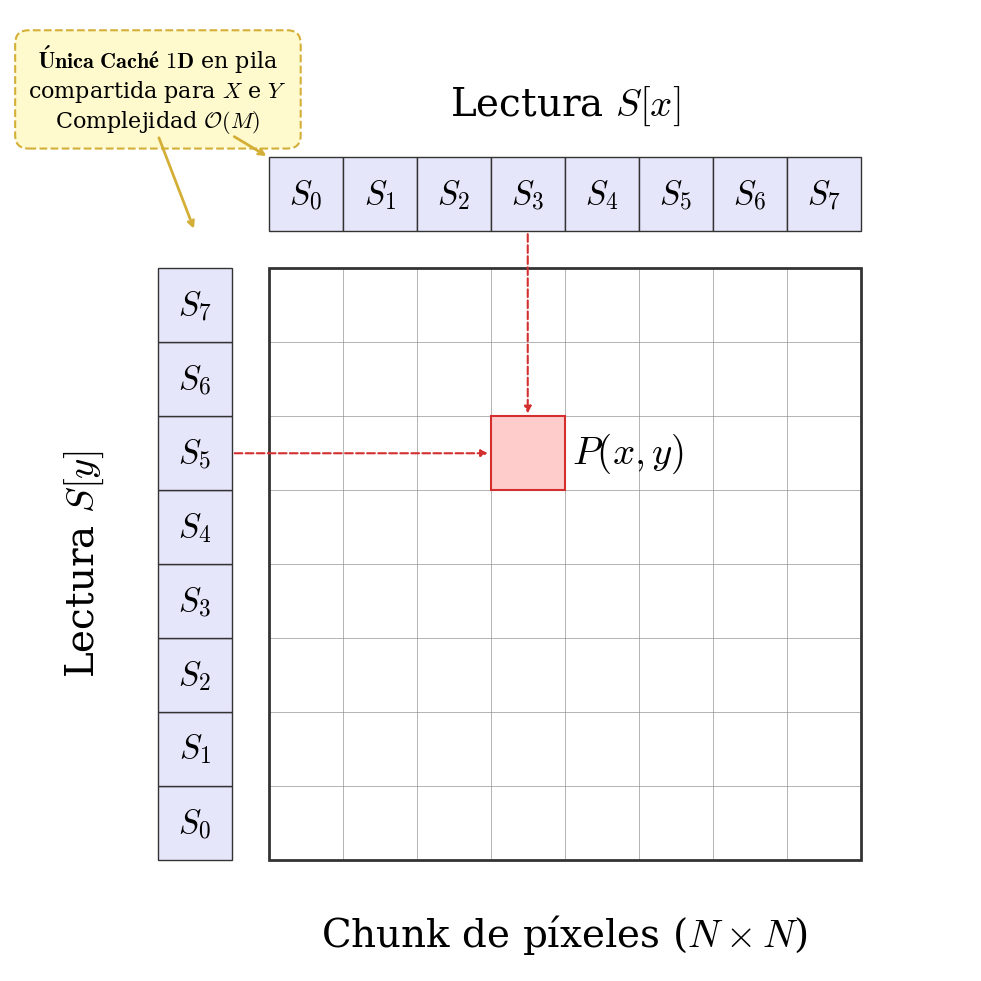

In [ ]:
# ==========================================
# --- PARÁMETROS DE CONFIGURACIÓN ---
# ==========================================
apply_common_style({'figure.autolayout': True})

PALETA = PALETA_CACHE

# Dimensiones y posiciones
N = 8                  # Tamaño del chunk (N x N) y de los cachés
PX_X = 3               # Posición X del píxel objetivo (0 a N-1)
PX_Y = 5               # Posición Y del píxel objetivo (0 a N-1)
FIG_SIZE = (10, 10)    # Tamaño de la figura (ancho, alto)

# Textos y nomenclaturas
CACHE_VAR = 'S'
TEXT_CHUNK = r'Chunk de píxeles ($N \times N$)'
TEXT_CACHE_X = r'Lectura $S[x]$'
TEXT_CACHE_Y = r'Lectura $S[y]$'
TEXT_PIXEL = r'$P(x,y)$'

# Tamaños de fuente
FONT_TITLE = 28        # Ajustado ligeramente para acomodar la nueva caja
FONT_VARS = 24

# Colores
COLOR_GRID = PALETA['grid']
COLOR_BORDER = PALETA['borde']
COLOR_CACHE_BG = PALETA['cache_bg']
COLOR_PIXEL_BG = PALETA['pixel_bg']
COLOR_PIXEL_EDGE = PALETA['pixel_edge']
COLOR_ARROW = PALETA['arrow']

# ==========================================
# --- INICIO DEL CÓDIGO DE DIBUJO ---
# ==========================================

# Configuración inicial de la figura
fig, ax = plt.subplots(figsize=FIG_SIZE)
ax.set_aspect('equal')
ax.axis('off')

# --- Dibujar la rejilla principal (Chunk N x N) ---
for i in range(N):
    for j in range(N):
        rect = patches.Rectangle((i, j), 1, 1, linewidth=0.5, edgecolor=COLOR_GRID, facecolor='none', alpha=0.5)
        ax.add_patch(rect)

# Borde exterior grueso
rect_main = patches.Rectangle((0, 0), N, N, linewidth=2, edgecolor=COLOR_BORDER, facecolor='none')
ax.add_patch(rect_main)

# Etiqueta inferior centrada
ax.text(N / 2, -1, TEXT_CHUNK, fontsize=FONT_TITLE, ha='center', va='center')

# --- Dibujar Vista de Caché Eje X (Arriba) ---
for i in range(N):
    rect = patches.Rectangle((i, N + 0.5), 1, 1,
                             linewidth=1, edgecolor=COLOR_BORDER, facecolor=COLOR_CACHE_BG)
    ax.add_patch(rect)
    ax.text(i + 0.5, N + 1, f'${CACHE_VAR}_{{{i}}}$', fontsize=FONT_VARS, ha='center', va='center')

ax.text(N / 2, N + 2.2, TEXT_CACHE_X, fontsize=FONT_TITLE, ha='center', va='center')

# --- Dibujar Vista de Caché Eje Y (Izquierda) ---
for i in range(N):
    rect = patches.Rectangle((-1.5, i), 1, 1,
                             linewidth=1, edgecolor=COLOR_BORDER, facecolor=COLOR_CACHE_BG)
    ax.add_patch(rect)
    ax.text(-1, i + 0.5, f'${CACHE_VAR}_{{{i}}}$', fontsize=FONT_VARS, ha='center', va='center')

ax.text(-2.5, N / 2, TEXT_CACHE_Y, fontsize=FONT_TITLE, ha='center', va='center', rotation=90)


# --- NUEVO: Indicador de Caché Única ---
# Creamos una caja unificadora en la esquina superior izquierda que enfatiza que es 1 sola caché
ax.text(-1.5, N + 1.8,
        r"$\bf{Única\ Caché\ 1D}$ en pila" + "\n" + r"compartida para $X$ e $Y$" + "\n" + r"Complejidad $\mathcal{O}(M)$",
        fontsize=16, ha='center', va='bottom',
        bbox=dict(facecolor=PALETA['info_bg'], edgecolor=PALETA['info_edge'], boxstyle='round,pad=0.6', ls='--', lw=1.5))

# Dibujar flechitas indicando que esa estructura alimenta ambos ejes
ax.annotate('', xy=(0, N+1.5), xytext=(-0.5, N+1.8), arrowprops=dict(arrowstyle='->', color=PALETA['info_edge'], lw=2))
ax.annotate('', xy=(-1, N+0.5), xytext=(-1.5, N+1.8), arrowprops=dict(arrowstyle='->', color=PALETA['info_edge'], lw=2))


# --- Dibujar Punto de ejemplo P(x,y) ---
rect_p = patches.Rectangle((PX_X, PX_Y), 1, 1,
                           linewidth=1.5, edgecolor=COLOR_PIXEL_EDGE, facecolor=COLOR_PIXEL_BG)
ax.add_patch(rect_p)
ax.text(PX_X + 1.1, PX_Y + 0.5, TEXT_PIXEL, fontsize=FONT_TITLE, ha='left', va='center')

# --- Dibujar Flechas de Lectura ---
# Flecha desde Caché X hacia P
start_x_arrow = (PX_X + 0.5, N + 0.5)
end_x_arrow = (PX_X + 0.5, PX_Y + 1)
ax.annotate('', xy=end_x_arrow, xytext=start_x_arrow,
            arrowprops=dict(arrowstyle='-|>', color=COLOR_ARROW, lw=1.5, ls='--'))

# Flecha desde Caché Y hacia P
start_y_arrow = (-0.5, PX_Y + 0.5)
end_y_arrow = (PX_X, PX_Y + 0.5)
ax.annotate('', xy=end_y_arrow, xytext=start_y_arrow,
            arrowprops=dict(arrowstyle='-|>', color=COLOR_ARROW, lw=1.5, ls='--'))

# ==========================================
# --- AJUSTES FINALES Y EXPORTACIÓN ---
# ==========================================

# Ajustar límites de la ventana dinámicamente ciñendo más el espacio
ax.set_xlim(-3.5, N + 1.5)
ax.set_ylim(-1.5, N + 3.5)

# Eliminar márgenes internos de la figura
plt.tight_layout()

# Guardar la imagen recortando automáticamente cualquier padding restante
plt.savefig("cacheado.png", dpi=300, bbox_inches='tight')

# Mostrar el gráfico en pantalla
plt.show()

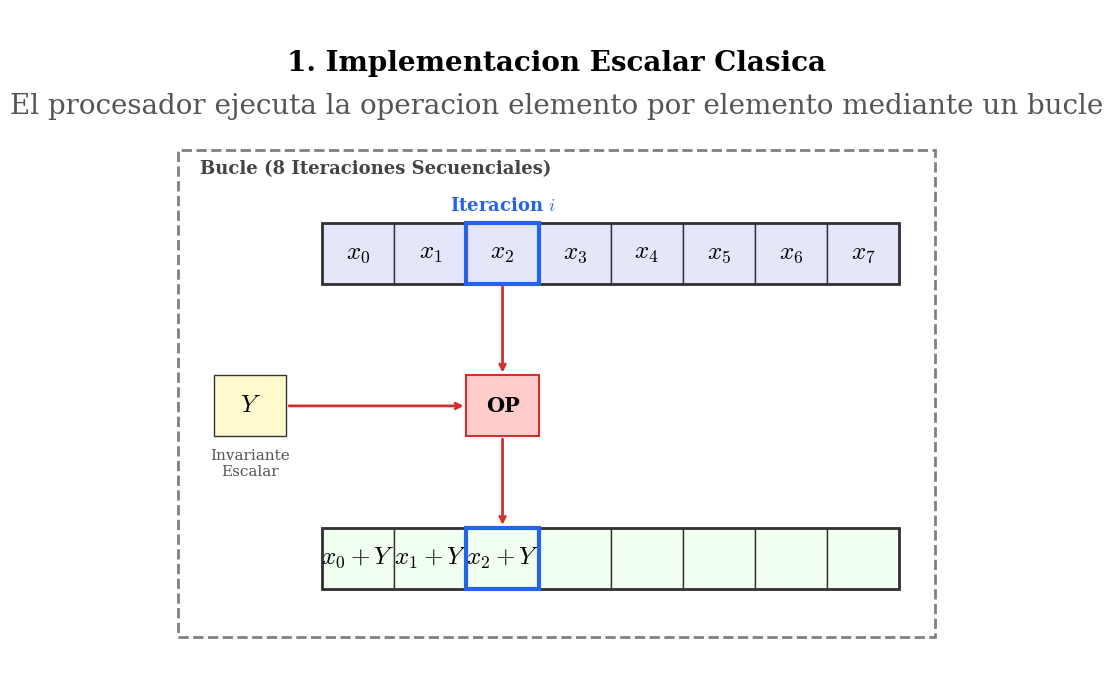

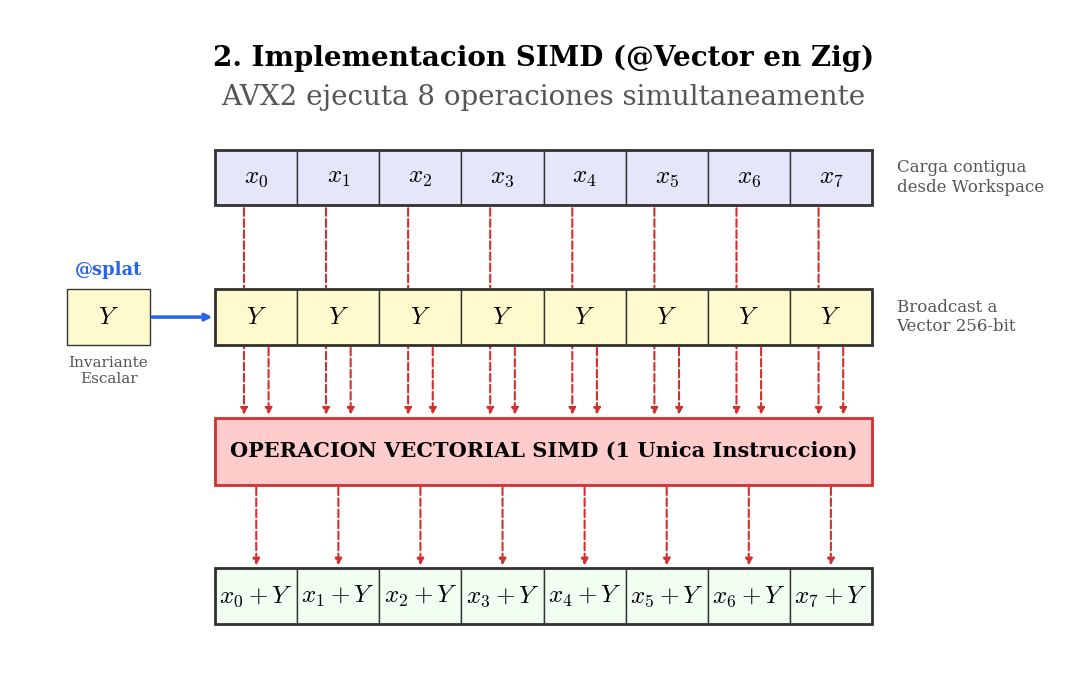

In [13]:
# ==========================================
# --- 1. CONFIGURACIÓN DE ABSTRACCIÓN ---
# ---    (ESTILO, COLORES, FUENTES)   ---
# ==========================================

# --- Dimensiones y lógica global ---
CONFIG_GLOBAL = {
    'N_ELEMENTOS': 8,           # Elementos (ej: AVX2 f32x8)
    'MARGEN_IZQ': 2.5,          # Espacio para etiquetas a la izquierda
    'TAMANO_FIGURA': (11, 7),   # (Ancho, Alto) en pulgadas
    'DPI_GUARDADO': 300,        # Resolución de exportación
}

PALETA = PALETA_SIMD

# --- Tamaño y estilo de fuentes ---
FUENTES = {
    'titulo_principal': {**FUENTE_TITULO_BASE, 'fontsize': FONT_SIZE_TITLE},
    'subtitulo': {**FUENTE_SUBTITULO_BASE, 'fontsize': 20},
    'etiqueta_bucle': {**FUENTE_ETIQUETA_BASE, 'fontsize': FONT_SIZE_LABEL},
    'dentro_celda': {**FUENTE_CELDA_BASE, 'fontsize': FONT_SIZE_CELL},
    'dentro_op_simd': {**FUENTE_CELDA_BOLD_BASE, 'fontsize': FONT_SIZE_CELL_BOLD},
    'dentro_op_esc': {**FUENTE_CELDA_BOLD_BASE, 'fontsize': FONT_SIZE_CELL_BOLD},
    'leyenda_escalar': {**FUENTE_LEYENDA_BASE, 'fontsize': FONT_SIZE_LEGEND},
    'splat_text': {**FUENTE_CELDA_BOLD_BASE, 'fontsize': FONT_SIZE_LABEL, 'color': PALETA['flecha_special']},
    'resaltado_iter': {**FUENTE_CELDA_BOLD_BASE, 'fontsize': FONT_SIZE_LABEL, 'color': PALETA['borde_resaltado']},
    'anotacion_mem': {**FUENTE_ANOTACION_BASE, 'fontsize': FONT_SIZE_NOTE},
}

# --- Estilos de línea y parches ---
ESTILOS_LINEA = {
    'borde_vector_grueso': {'lw': 2, 'edgecolor': PALETA['borde_normal']},
    'borde_celda_fino': {'lw': 1, 'edgecolor': PALETA['borde_normal']},
    'caja_bucle': {'lw': 2, 'edgecolor': 'gray', 'ls': '--'},
    'resaltado_celda': {'lw': 3, 'edgecolor': PALETA['borde_resaltado']},
    'caja_operacion': {'lw': 2, 'edgecolor': PALETA['flecha_principal']},
}

# --- Estilos de flechas ---
ESTILOS_FLECHA = {
    'estandar': dict(arrowstyle='->', color=PALETA['flecha_principal'], lw=2),
    'simd_dash': dict(arrowstyle='-|>', color=PALETA['flecha_principal'], lw=1.5, ls='--'),
    'splat': dict(arrowstyle='->', color=PALETA['flecha_special'], lw=2.5),
}

N = CONFIG_GLOBAL['N_ELEMENTOS']
X_START = CONFIG_GLOBAL['MARGEN_IZQ']

# ==========================================
# --- 2. FUNCIÓN AUXILIAR ---
# ==========================================
def draw_vector(ax, x, y, labels, facecolor, zorder_base=2):
    """Dibuja un vector de N elementos usando la configuración abstracta."""
    ax.add_patch(
        patches.Rectangle(
            (x, y),
            N,
            1,
            fill=False,
            zorder=zorder_base + 1,
            **ESTILOS_LINEA['borde_vector_grueso'],
        )
    )
    for i in range(N):
        ax.add_patch(
            patches.Rectangle(
                (x + i, y),
                1,
                1,
                facecolor=facecolor,
                zorder=zorder_base,
                **ESTILOS_LINEA['borde_celda_fino'],
            )
        )
        ax.text(
            x + i + 0.5,
            y + 0.5,
            labels[i],
            ha='center',
            va='center',
            zorder=zorder_base + 2,
            **FUENTES['dentro_celda'],
        )

# ==========================================
# --- 3. FIGURA 1: ESCALAR ---
# ==========================================
fig1, ax1 = plt.subplots(figsize=CONFIG_GLOBAL['TAMANO_FIGURA'])
ax1.axis('off')

Y_A = 6.0
Y_OP = 3.5
Y_RES = 1.0
ACTUAL_I = 2

X_CENTER_FIG1 = 0.5 + (N + 2.5) / 2
ax1.text(X_CENTER_FIG1, 9.5, '1. Implementacion Escalar Clasica', ha='center', **FUENTES['titulo_principal'])
ax1.text(
    X_CENTER_FIG1,
    8.8,
    'El procesador ejecuta la operacion elemento por elemento mediante un bucle',
    ha='center',
    **FUENTES['subtitulo'],
)

ax1.add_patch(patches.Rectangle((0.5, 0.2), N + 2.5, 8.0, fill=False, **ESTILOS_LINEA['caja_bucle']))
ax1.text(
    0.8,
    7.8,
    'Bucle (8 Iteraciones Secuenciales)',
    bbox=dict(facecolor='white', edgecolor='none', pad=2),
    **FUENTES['etiqueta_bucle'],
)

draw_vector(ax1, X_START, Y_A, [f'$x_{{{i}}}$' for i in range(N)], PALETA['fondo_vector_x'])

ax1.add_patch(
    patches.Rectangle((X_START + ACTUAL_I, Y_A), 1, 1, fill=False, zorder=5, **ESTILOS_LINEA['resaltado_celda'])
)
ax1.text(X_START + ACTUAL_I + 0.5, Y_A + 1.2, 'Iteracion $i$', ha='center', **FUENTES['resaltado_iter'])

ax1.add_patch(
    patches.Rectangle((X_START - 1.5, Y_OP), 1, 1, facecolor=PALETA['fondo_escalar_y'], **ESTILOS_LINEA['borde_celda_fino'])
)
ax1.text(X_START - 1.0, Y_OP + 0.5, '$Y$', va='center', ha='center', fontsize=18)
ax1.text(X_START - 1.0, Y_OP - 0.2, 'Invariante\nEscalar', **FUENTES['leyenda_escalar'])

ax1.add_patch(
    patches.Rectangle((X_START + ACTUAL_I, Y_OP), 1, 1, facecolor=PALETA['fondo_operacion'], edgecolor=PALETA['flecha_principal'], lw=1.5)
)
ax1.text(X_START + ACTUAL_I + 0.5, Y_OP + 0.5, 'OP', va='center', ha='center', **FUENTES['dentro_op_esc'])

res_labels_s = [f'$x_{{{i}}}+Y$' if i <= ACTUAL_I else '' for i in range(N)]
draw_vector(ax1, X_START, Y_RES, res_labels_s, PALETA['fondo_resultado'])
ax1.add_patch(
    patches.Rectangle((X_START + ACTUAL_I, Y_RES), 1, 1, fill=False, zorder=5, **ESTILOS_LINEA['resaltado_celda'])
)

ax1.annotate('', xy=(X_START + ACTUAL_I + 0.5, Y_OP + 1), xytext=(X_START + ACTUAL_I + 0.5, Y_A), arrowprops=ESTILOS_FLECHA['estandar'])
ax1.annotate('', xy=(X_START + ACTUAL_I, Y_OP + 0.5), xytext=(X_START - 0.5, Y_OP + 0.5), arrowprops=ESTILOS_FLECHA['estandar'])
ax1.annotate('', xy=(X_START + ACTUAL_I + 0.5, Y_RES + 1), xytext=(X_START + ACTUAL_I + 0.5, Y_OP), arrowprops=ESTILOS_FLECHA['estandar'])

ax1.set_xlim(0, X_START + N + 1)
ax1.set_ylim(-0.5, 10.5)
plt.tight_layout()
fig1.savefig('escalar.png', dpi=CONFIG_GLOBAL['DPI_GUARDADO'], bbox_inches='tight', pad_inches=0.1)

# ==========================================
# --- 4. FIGURA 2: SIMD ---
# ==========================================
fig2, ax2 = plt.subplots(figsize=CONFIG_GLOBAL['TAMANO_FIGURA'])
ax2.axis('off')

Y_X_V = 7.0
Y_Y_V = 4.5
Y_OP_V = 2.0
Y_RES_V = -0.5

ax2.text(X_START + N / 2, 9.5, r'2. Implementacion SIMD (@Vector en Zig)', ha='center', **FUENTES['titulo_principal'])
ax2.text(X_START + N / 2, 8.8, 'AVX2 ejecuta 8 operaciones simultaneamente', ha='center', **FUENTES['subtitulo'])

draw_vector(ax2, X_START, Y_X_V, [f'$x_{{{i}}}$' for i in range(N)], PALETA['fondo_vector_x'])
ax2.text(X_START + N + 0.3, Y_X_V + 0.5, 'Carga contigua\ndesde Workspace', va='center', **FUENTES['anotacion_mem'])

ax2.add_patch(
    patches.Rectangle((X_START - 1.8, Y_Y_V), 1, 1, facecolor=PALETA['fondo_escalar_y'], **ESTILOS_LINEA['borde_celda_fino'])
)
ax2.text(X_START - 1.3, Y_Y_V + 0.5, '$Y$', va='center', ha='center', fontsize=18)
ax2.text(X_START - 1.3, Y_Y_V - 0.2, 'Invariante\nEscalar', **FUENTES['leyenda_escalar'])

ax2.annotate('', xy=(X_START, Y_Y_V + 0.5), xytext=(X_START - 0.8, Y_Y_V + 0.5), arrowprops=ESTILOS_FLECHA['splat'])
ax2.text(X_START - 1.3, Y_Y_V + 1.25, '@splat', ha='center', **FUENTES['splat_text'])

draw_vector(ax2, X_START, Y_Y_V, ['$Y$' for _ in range(N)], PALETA['fondo_escalar_y'], zorder_base=3)
ax2.text(X_START + N + 0.3, Y_Y_V + 0.5, 'Broadcast a\nVector 256-bit', va='center', **FUENTES['anotacion_mem'])

ax2.add_patch(
    patches.Rectangle((X_START, Y_OP_V), N, 1.2, facecolor=PALETA['fondo_operacion'], **ESTILOS_LINEA['caja_operacion'])
)
ax2.text(
    X_START + N / 2,
    Y_OP_V + 0.6,
    'OPERACION VECTORIAL SIMD (1 Unica Instruccion)',
    va='center',
    ha='center',
    **FUENTES['dentro_op_simd'],
)

res_labels_v = [f'$x_{{{i}}}+Y$' for i in range(N)]
draw_vector(ax2, X_START, Y_RES_V, res_labels_v, PALETA['fondo_resultado'])

for i in range(N):
    x_pos_X = X_START + i + 0.35
    x_pos_Y = X_START + i + 0.65
    x_pos_R = X_START + i + 0.5

    ax2.annotate('', xy=(x_pos_X, Y_OP_V + 1.2), xytext=(x_pos_X, Y_X_V), arrowprops=ESTILOS_FLECHA['simd_dash'], zorder=1)
    ax2.annotate('', xy=(x_pos_Y, Y_OP_V + 1.2), xytext=(x_pos_Y, Y_Y_V), arrowprops=ESTILOS_FLECHA['simd_dash'], zorder=4)
    ax2.annotate('', xy=(x_pos_R, Y_RES_V + 1), xytext=(x_pos_R, Y_OP_V), arrowprops=ESTILOS_FLECHA['simd_dash'], zorder=4)

ax2.set_xlim(0, X_START + N + 2.5)
ax2.set_ylim(-1.5, 10.5)
plt.tight_layout()
fig2.savefig('vectorial.png', dpi=CONFIG_GLOBAL['DPI_GUARDADO'], bbox_inches='tight')

plt.show()

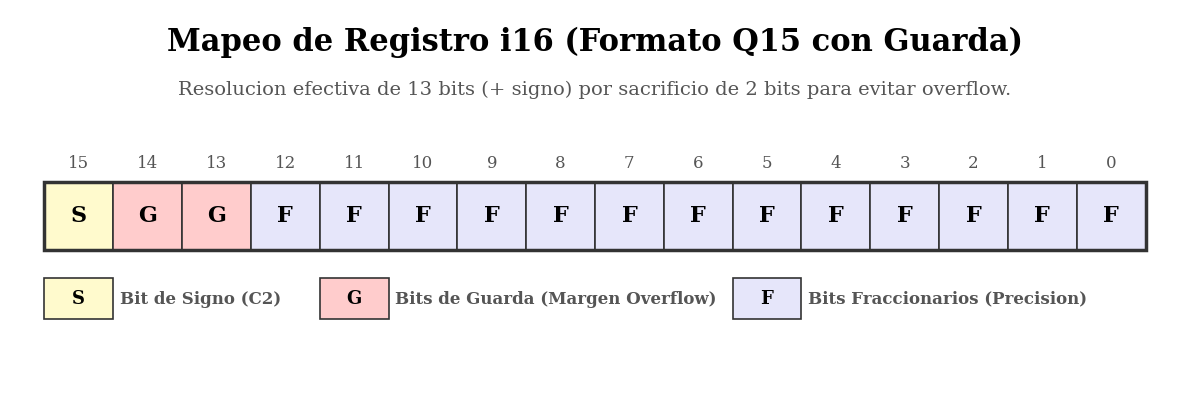

In [12]:
# ==========================================
# --- CONFIGURACIÓN DE ESTILO ESTANDARIZADO ---
# ==========================================
apply_common_style({'figure.autolayout': True})

PALETA = PALETA_BITS

N_BITS = 16
FIG_SIZE = (12, 4.5)

fig, ax = plt.subplots(figsize=FIG_SIZE, dpi=100)
ax.axis('off')
ax.set_aspect('equal')

# Coordenadas base
x_start = 0
y_base = 1.5
cell_h = 1.0
cell_w = 1.0

# --- DIBUJO DE CASILLAS Y ETIQUETAS ---
for i in range(N_BITS):
    bit_real = (N_BITS - 1) - i
    x_pos = x_start + i

    if bit_real == 15:
        label_inside = 'S'
        color = PALETA['S']
    elif bit_real in [14, 13]:
        label_inside = 'G'
        color = PALETA['G']
    else:
        label_inside = 'F'
        color = PALETA['F']

    rect = patches.Rectangle((x_pos, y_base), cell_w, cell_h, facecolor=color, edgecolor=PALETA['borde'], lw=1.2, zorder=2)
    ax.add_patch(rect)

    ax.text(
        x_pos + 0.5,
        y_base + 0.5,
        label_inside,
        fontsize=FONT_SIZE_CELL_MEDIUM,
        fontweight='bold',
        ha='center',
        va='center',
        color=PALETA['texto_bit'],
        zorder=3,
    )

    ax.text(
        x_pos + 0.5,
        y_base + cell_h + 0.15,
        str(bit_real),
        fontsize=FONT_SIZE_NOTE,
        ha='center',
        va='bottom',
        color=PALETA['texto_leyenda'],
        zorder=3,
    )

# --- BORDES DE GRUPO ---
ax.add_patch(patches.Rectangle((x_start, y_base), N_BITS, cell_h, fill=False, edgecolor=PALETA['borde'], lw=2.5, zorder=4))

# --- TITULOS ---
ax.text(
    x_start + N_BITS / 2,
    y_base + cell_h + 1.8,
    'Mapeo de Registro i16 (Formato Q15 con Guarda)',
    fontsize=FONT_SIZE_TITLE_LARGE,
    ha='center',
    va='bottom',
    color=PALETA['texto_bit'],
    fontweight='bold',
)

ax.text(
    x_start + N_BITS / 2,
    y_base + cell_h + 1.2,
    'Resolucion efectiva de 13 bits (+ signo) por sacrificio de 2 bits para evitar overflow.',
    fontsize=FONT_SIZE_SUBTITLE,
    ha='center',
    va='bottom',
    color=PALETA['texto_leyenda'],
)

# --- LEYENDAS INFERIORES ---
y_leg = y_base - 0.7

x_leg_S = x_start + 0
ax.add_patch(patches.Rectangle((x_leg_S, y_leg - 0.3), 1, 0.6, facecolor=PALETA['S'], edgecolor=PALETA['borde'], lw=1.2, zorder=2))
ax.text(x_leg_S + 0.5, y_leg, 'S', fontsize=FONT_SIZE_LABEL, fontweight='bold', ha='center', va='center', color=PALETA['texto_bit'], zorder=3)
ax.text(x_leg_S + 1.1, y_leg, 'Bit de Signo (C2)', fontsize=FONT_SIZE_NOTE, fontweight='bold', ha='left', va='center', color=PALETA['texto_leyenda'], zorder=3)

x_leg_G = x_start + 4
ax.add_patch(patches.Rectangle((x_leg_G, y_leg - 0.3), 1, 0.6, facecolor=PALETA['G'], edgecolor=PALETA['borde'], lw=1.2, zorder=2))
ax.text(x_leg_G + 0.5, y_leg, 'G', fontsize=FONT_SIZE_LABEL, fontweight='bold', ha='center', va='center', color=PALETA['texto_bit'], zorder=3)
ax.text(x_leg_G + 1.1, y_leg, 'Bits de Guarda (Margen Overflow)', fontsize=FONT_SIZE_NOTE, fontweight='bold', ha='left', va='center', color=PALETA['texto_leyenda'], zorder=3)

x_leg_F = x_start + 10
ax.add_patch(patches.Rectangle((x_leg_F, y_leg - 0.3), 1, 0.6, facecolor=PALETA['F'], edgecolor=PALETA['borde'], lw=1.2, zorder=2))
ax.text(x_leg_F + 0.5, y_leg, 'F', fontsize=FONT_SIZE_LABEL, fontweight='bold', ha='center', va='center', color=PALETA['texto_bit'], zorder=3)
ax.text(x_leg_F + 1.1, y_leg, 'Bits Fraccionarios (Precision)', fontsize=FONT_SIZE_NOTE, fontweight='bold', ha='left', va='center', color=PALETA['texto_leyenda'], zorder=3)

ax.set_xlim(-0.5, N_BITS + 0.5)
ax.set_ylim(-0.5, 5.0)

plt.savefig('Q15.png', dpi=300, bbox_inches='tight')
plt.show()

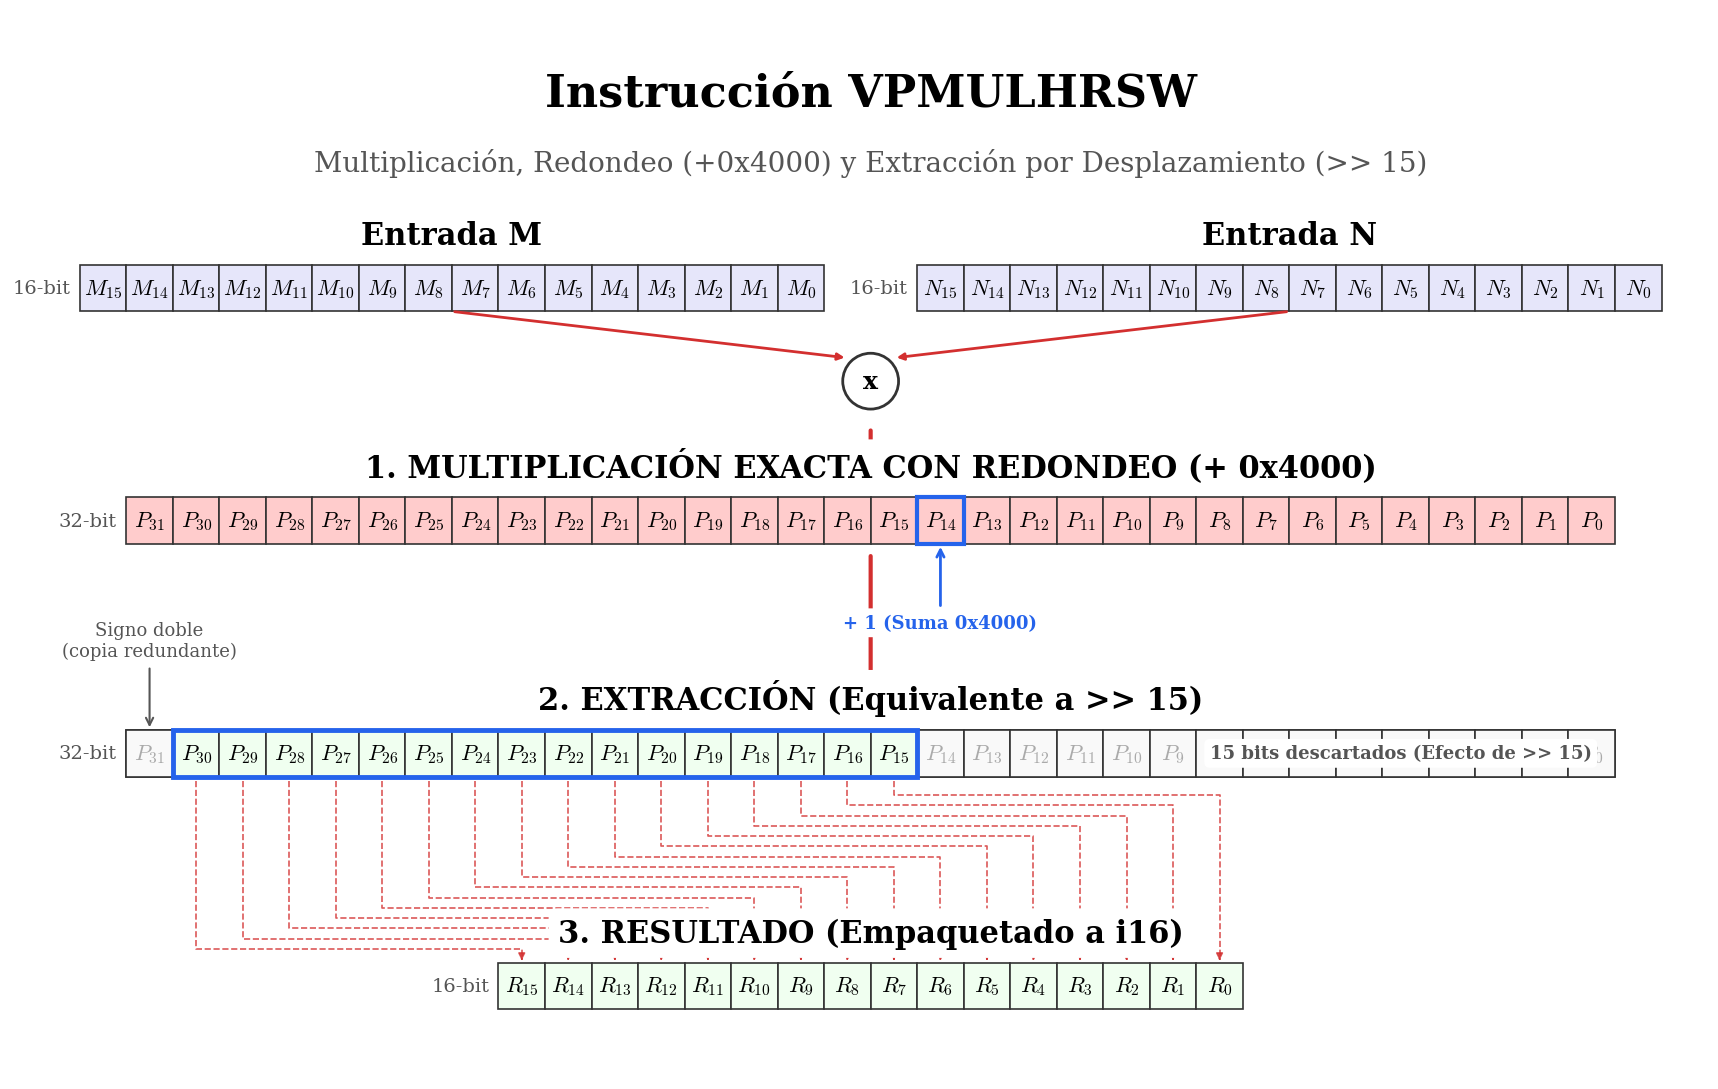

In [11]:
# ==========================================
# --- CONFIGURACIÓN DE ESTILO Y COLORES ---
# ==========================================
apply_common_style()

PALETA = PALETA_VPMULHRSW

BBOX_BLANCO = dict(boxstyle='round,pad=0.3', facecolor=COLOR_BLANCO, edgecolor='none', alpha=1)

# ==========================================
# --- PARÁMETROS GEOMÉTRICOS ---
# ==========================================
N16 = 16
N32 = 32

Y_IN = 19.5
Y_MULT_ROUND = 14.5
Y_SHIFT = 9.5
Y_OUT = 4.5

Y_TITULO_PRINCIPAL = 24.2
Y_SUBTITULO = 22.7

X_32 = 0
X_IN_16_M = -1
X_IN_16_N = 17
X_OUT_16_OUT = 8

# ==========================================
# --- FUNCIÓN DE DIBUJO DE REGISTROS ---
# ==========================================
def draw_register(ax, x_start, y_start, n_bits, title, labels, color, label_left=''):
    if title:
        ax.text(
            x_start + n_bits / 2,
            y_start + 1.3,
            title,
            fontsize=FONT_SIZE_TITLE_LARGE,
            fontweight='bold',
            ha='center',
            va='bottom',
            color=PALETA['texto_main'],
            bbox=BBOX_BLANCO,
            zorder=10,
        )

    if label_left:
        ax.text(
            x_start - 0.2,
            y_start + 0.5,
            label_left,
            fontsize=FONT_SIZE_SUBTITLE,
            ha='right',
            va='center',
            color=PALETA['texto_sub'],
            bbox=BBOX_BLANCO,
            zorder=10,
        )

    for i in range(n_bits):
        rect = patches.Rectangle((x_start + i, y_start), 1, 1, facecolor=color, edgecolor=PALETA['borde'], lw=1.2, zorder=2)
        ax.add_patch(rect)
        if labels:
            ax.text(x_start + i + 0.5, y_start + 0.5, labels[i], fontsize=FONT_SIZE_CELL_MEDIUM, ha='center', va='center', zorder=3)

# ==========================================
# --- GENERACIÓN DE LA FIGURA ---
# ==========================================
fig, ax = plt.subplots(figsize=(18, 11), dpi=100)
ax.axis('off')
ax.set_aspect('equal')

# --- 1. TÍTULOS PRINCIPALES ---
ax.text(16, Y_TITULO_PRINCIPAL, 'Instrucción VPMULHRSW', fontsize=FONT_SIZE_TITLE_SIMD, fontweight='bold', ha='center', va='center', zorder=10, bbox=BBOX_BLANCO)
ax.text(
    16,
    Y_SUBTITULO,
    'Multiplicación, Redondeo (+0x4000) y Extracción por Desplazamiento (>> 15)',
    fontsize=FONT_SIZE_TITLE,
    ha='center',
    va='center',
    color=PALETA['texto_sub'],
    zorder=10,
    bbox=BBOX_BLANCO,
)

# --- 2. GENERACIÓN DE ETIQUETAS ---
labels_m = [f'$M_{{{15 - i}}}$' for i in range(N16)]
labels_n = [f'$N_{{{15 - i}}}$' for i in range(N16)]
labels_32 = [f'$P_{{{31 - i}}}$' for i in range(N32)]
labels_res = [f'$R_{{{15 - i}}}$' for i in range(N16)]

# --- 3. DIBUJO DE LOS REGISTROS ---
draw_register(ax, X_IN_16_M, Y_IN, N16, 'Entrada M', labels_m, PALETA['entrada'], '16-bit')
draw_register(ax, X_IN_16_N, Y_IN, N16, 'Entrada N', labels_n, PALETA['entrada'], '16-bit')

draw_register(
    ax,
    X_32,
    Y_MULT_ROUND,
    N32,
    '1. MULTIPLICACIÓN EXACTA CON REDONDEO (+ 0x4000)',
    labels_32,
    PALETA['op_interna'],
    '32-bit',
)

draw_register(ax, X_32, Y_SHIFT, N32, '2. EXTRACCIÓN (Equivalente a >> 15)', labels_32, PALETA['resultado'], '32-bit')

draw_register(ax, X_OUT_16_OUT, Y_OUT, N16, '3. RESULTADO (Empaquetado a i16)', labels_res, PALETA['resultado'], '16-bit')

# ==========================================
# --- 4. FLECHAS DE FLUJO Y DETALLES ---
# ==========================================
circle_mult = patches.Circle((16, Y_IN - 1.5), 0.6, facecolor='white', edgecolor=PALETA['borde'], lw=2, zorder=10)
ax.add_patch(circle_mult)
ax.text(16, Y_IN - 1.5, 'x', fontsize=FONT_SIZE_CELL, fontweight='bold', ha='center', va='center', zorder=11)

ax.annotate('', xy=(15.5, Y_IN - 1), xytext=(X_IN_16_M + 8, Y_IN), arrowprops=dict(arrowstyle='-|>', color=PALETA['flecha_principal'], lw=2), zorder=4)
ax.annotate('', xy=(16.5, Y_IN - 1), xytext=(X_IN_16_N + 8, Y_IN), arrowprops=dict(arrowstyle='-|>', color=PALETA['flecha_principal'], lw=2), zorder=4)
ax.annotate('', xy=(16, Y_MULT_ROUND + 1.1), xytext=(16, Y_IN - 2.5), arrowprops=dict(arrowstyle='-|>', color=PALETA['flecha_principal'], lw=3), zorder=4)

bit_14_x = 17
rect_resalte_14 = patches.Rectangle((bit_14_x, Y_MULT_ROUND), 1, 1, fill=False, edgecolor=PALETA['flecha_resalte'], lw=3, zorder=5)
ax.add_patch(rect_resalte_14)
ax.annotate(
    '+ 1 (Suma 0x4000)',
    xy=(bit_14_x + 0.5, Y_MULT_ROUND),
    xytext=(bit_14_x + 0.5, Y_MULT_ROUND - 1.5),
    arrowprops=dict(arrowstyle='->', color=PALETA['flecha_resalte'], lw=2),
    fontsize=FONT_SIZE_LABEL,
    color=PALETA['flecha_resalte'],
    ha='center',
    va='top',
    fontweight='bold',
    bbox=BBOX_BLANCO,
    zorder=10,
)

ax.annotate('', xy=(16, Y_SHIFT + 1.1), xytext=(16, Y_MULT_ROUND - 0.2), arrowprops=dict(arrowstyle='-|>', color=PALETA['flecha_principal'], lw=3), zorder=4)

for i in range(N32):
    bit_val = 31 - i
    if bit_val == 31 or bit_val <= 14:
        rect = patches.Rectangle((X_32 + i, Y_SHIFT), 1, 1, facecolor=PALETA['descartado'], edgecolor=PALETA['borde'], lw=1.2, zorder=4)
        ax.add_patch(rect)
        ax.text(
            X_32 + i + 0.5,
            Y_SHIFT + 0.5,
            labels_32[i],
            fontsize=FONT_SIZE_CELL_MEDIUM,
            ha='center',
            va='center',
            zorder=5,
            color=PALETA['texto_descartado'],
        )

rect_zona_util = patches.Rectangle((1, Y_SHIFT), 16, 1, fill=False, edgecolor=PALETA['borde_resalte'], lw=3.5, zorder=6)
ax.add_patch(rect_zona_util)

ax.annotate(
    'Signo doble\n(copia redundante)',
    xy=(0.5, Y_SHIFT + 1),
    xytext=(0.5, Y_SHIFT + 2.5),
    arrowprops=dict(arrowstyle='->', color=PALETA['texto_sub'], lw=1.5),
    fontsize=FONT_SIZE_LABEL,
    color=PALETA['texto_sub'],
    ha='center',
    va='bottom',
    bbox=BBOX_BLANCO,
    zorder=10,
)

ax.text(
    X_32 + 31.5,
    Y_SHIFT + 0.5,
    '15 bits descartados (Efecto de >> 15)',
    fontsize=FONT_SIZE_LABEL,
    fontweight='bold',
    ha='right',
    va='center',
    color=PALETA['texto_sub'],
    bbox=BBOX_BLANCO,
    zorder=10,
)

# --- ENRUTAMIENTO ORTOGONAL ESCALONADO ---
# Mantenemos Rojo Intenso para el flujo final, pero con estilo discontinuo
for i in range(N16):
    bit_sh_idx = i + 1
    start_x = X_32 + bit_sh_idx + 0.5
    end_x = X_OUT_16_OUT + i + 0.5
    start_y = Y_SHIFT - 0.1
    end_y = Y_OUT + 1.05

    mid_y = start_y - 0.3 - (15 - i) * 0.22

    # Línea principal
    ax.plot([start_x, start_x, end_x, end_x],
            [start_y, mid_y, mid_y, end_y],
            color=PALETA['flecha_principal'], lw=1.2, ls='--', zorder=4, alpha=0.8)

    # Punta de flecha
    ax.annotate('', xy=(end_x, end_y), xytext=(end_x, end_y + 0.1),
                arrowprops=dict(arrowstyle='-|>', color=PALETA['flecha_principal'], lw=1.2, alpha=0.8), zorder=4)

# ==========================================
# --- RENDERIZADO Y LÍMITES ---
# ==========================================
ax.set_xlim(-2.5, 34)
ax.set_ylim(3.0, 26.0)

plt.tight_layout()
# Nombre de archivo actualizado para reflejar el cambio de color
plt.savefig('vpmulhrsw.png', dpi=300, bbox_inches='tight', pad_inches=0.1)
plt.show()

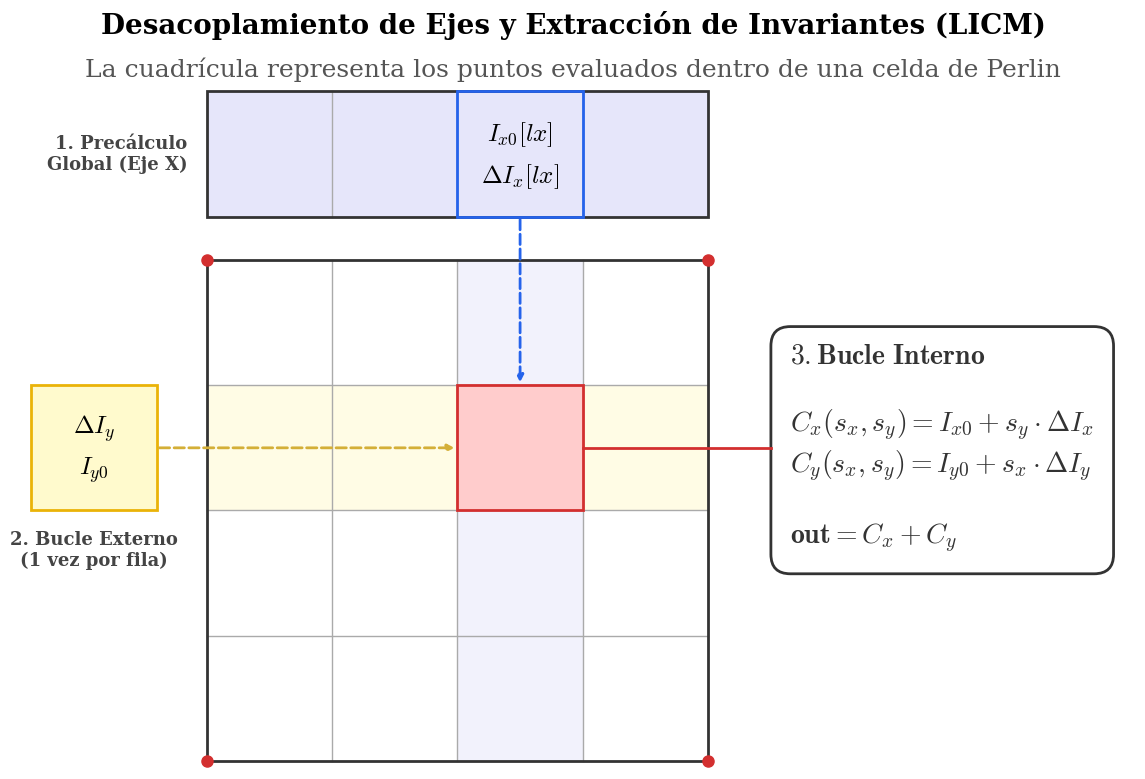

In [10]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches

PALETA = {
    'fondo_cuadricula': COLOR_BLANCO,
    'fondo_vector_x': COLOR_LAVANDA,
    'fondo_escalar_y': COLOR_AMARILLO_PASTEL,
    'fondo_operacion': COLOR_ROJO_PASTEL,
    'borde': COLOR_BORDE_OSCURO,
    'borde_normal': COLOR_BORDE_OSCURO,
    'borde_resalte': COLOR_AZUL_ACENTO,
    'borde_resaltado': COLOR_AZUL_ACENTO,
    'flecha_principal': COLOR_ROJO_ACENTO,
}

FUENTES = {
    **FUENTES,
    'titulo_secundario': {**FUENTE_SUBTITULO_BASE, 'fontsize': 18},
    'codigo_interno': {**FUENTE_ANOTACION_BASE, 'fontsize': 20, 'color': COLOR_BORDE_OSCURO},
}

ESTILOS_FLECHA = {
    **ESTILOS_FLECHA,
    'propagacion_x': dict(arrowstyle='-|>', color=PALETA['borde_resaltado'], lw=2, ls='--'),
    'propagacion_y': dict(arrowstyle='-|>', color=COLOR_DORADO, lw=2, ls='--'),
}

# ==========================================
# --- 1. CONFIGURACIÓN DE ABSTRACCIÓN ---
# ==========================================

CONFIG_GLOBAL = {
    'ESCALA_CELDA': 4,
    'MARGEN_IZQ': 2.5,
    'MARGEN_INF': 1.0,
    'TAMAÑO_FIGURA': (12, 9),
    'DPI_GUARDADO': 300
}

LW_PRINCIPAL = 2

ESTILOS_LINEA = {
    'borde_vector_grueso': {'lw': LW_PRINCIPAL, 'edgecolor': PALETA['borde']},
    'borde_cell_fino': {'lw': 1, 'edgecolor': '#AAAAAA'},
    'resaltado_celda': {'lw': LW_PRINCIPAL, 'edgecolor': PALETA['borde_resalte']},
    'caja_operacion': {'lw': LW_PRINCIPAL, 'edgecolor': PALETA['flecha_principal']},
    'bloque_y_resaltado': {'lw': LW_PRINCIPAL, 'edgecolor': '#EAB308'},
}

S = CONFIG_GLOBAL['ESCALA_CELDA']
CELL = 1.6 
GRID = S * CELL
X0 = CONFIG_GLOBAL['MARGEN_IZQ']
Y0 = CONFIG_GLOBAL['MARGEN_INF']

LX_CRITICO = 2
LY_CRITICO = 2
x_crit = X0 + LX_CRITICO * CELL
y_crit = Y0 + LY_CRITICO * CELL
x_crit_c = x_crit + 0.5 * CELL
y_crit_c = y_crit + 0.5 * CELL

X_INFO = X0 + GRID + 1.05
X_MAX_LIMIT = X_INFO + 4.4 
X_CENTER_CANVAS = X_MAX_LIMIT / 2

# ==========================================
# --- 2. GENERACIÓN DE LA FIGURA ---
# ==========================================
fig, ax = plt.subplots(figsize=CONFIG_GLOBAL['TAMAÑO_FIGURA'])
ax.axis('off')
ax.set_aspect('equal', adjustable='box')

# --- Títulos ---
ax.text(X_CENTER_CANVAS, Y0 + GRID + 2.9, 'Desacoplamiento de Ejes y Extracción de Invariantes (LICM)',
        ha='center', **FUENTES['titulo_principal'])
ax.text(X_CENTER_CANVAS, Y0 + GRID + 2.35, 'La cuadrícula representa los puntos evaluados dentro de una celda de Perlin',
        ha='center', **FUENTES['titulo_secundario'])

# --- A. CUADRÍCULA (CELDA 2D) ---
ax.add_patch(patches.Rectangle((X0, Y0), GRID, GRID, facecolor=PALETA['fondo_cuadricula'],
                               edgecolor='none', zorder=1))

for i in range(1, S):
    x_i = X0 + i * CELL
    y_i = Y0 + i * CELL
    ax.plot([x_i, x_i], [Y0, Y0 + GRID], color=ESTILOS_LINEA['borde_cell_fino']['edgecolor'], lw=1, zorder=2)
    ax.plot([X0, X0 + GRID], [y_i, y_i], color=ESTILOS_LINEA['borde_cell_fino']['edgecolor'], lw=1, zorder=2)

ax.add_patch(patches.Rectangle((X0, Y0), GRID, GRID, fill=False,
                               zorder=3, **ESTILOS_LINEA['borde_vector_grueso']))

esquinas = [(X0, Y0), (X0 + GRID, Y0), (X0, Y0 + GRID), (X0 + GRID, Y0 + GRID)]
for (ex, ey) in esquinas:
    ax.plot(ex, ey, marker='o', color=PALETA['flecha_principal'], markersize=8, zorder=5)

# --- B. INVARIANTES GLOBALES (EJE X) ---
Y_ARRAY_X = Y0 + GRID + 0.55
ax.add_patch(patches.Rectangle((X0, Y_ARRAY_X), GRID, CELL, facecolor=PALETA['fondo_vector_x'],
                               edgecolor='none', zorder=2))

for i in range(1, S):
    x_i = X0 + i * CELL
    ax.plot([x_i, x_i], [Y_ARRAY_X, Y_ARRAY_X + CELL], 
            color=ESTILOS_LINEA['borde_cell_fino']['edgecolor'], lw=1, zorder=3)

ax.add_patch(patches.Rectangle((X0, Y_ARRAY_X), GRID, CELL, fill=False,
                               zorder=4, **ESTILOS_LINEA['borde_vector_grueso']))

ax.text(X0 - 0.25, Y_ARRAY_X + 0.5 * CELL, '1. Precálculo\nGlobal (Eje X)', ha='right', va='center',
        **FUENTES['etiqueta_bucle'])

ax.add_patch(patches.Rectangle((x_crit, Y_ARRAY_X), CELL, CELL, fill=False,
                               zorder=5, **ESTILOS_LINEA['resaltado_celda']))

ax.text(x_crit_c, Y_ARRAY_X + 0.66 * CELL, r'$I_{x0}[lx]$', ha='center', va='center', **FUENTES['dentro_celda'])
ax.text(x_crit_c, Y_ARRAY_X + 0.33 * CELL, r'$\Delta I_{x}[lx]$', ha='center', va='center', **FUENTES['dentro_celda'])

ax.add_patch(patches.Rectangle((x_crit, Y0), CELL, GRID, facecolor=PALETA['fondo_vector_x'], alpha=0.5, zorder=1))
ax.annotate('', xy=(x_crit_c, y_crit + CELL), xytext=(x_crit_c, Y_ARRAY_X),
            arrowprops=ESTILOS_FLECHA['propagacion_x'])

# --- C. INVARIANTES BUCLE EXTERNO (EJE Y) ---
LADO_Y = CELL
X_ARRAY_Y = X0 - 1.4 * CELL 
Y_ARRAY_Y = y_crit

ax.add_patch(patches.Rectangle((X_ARRAY_Y, Y_ARRAY_Y), LADO_Y, LADO_Y, facecolor=PALETA['fondo_escalar_y'],
                               zorder=3, **ESTILOS_LINEA['bloque_y_resaltado']))

ax.text(X_ARRAY_Y + 0.5 * LADO_Y, Y_ARRAY_Y - 0.25, '2. Bucle Externo\n(1 vez por fila)', ha='center', va='top',
        **FUENTES['etiqueta_bucle'])

ax.text(X_ARRAY_Y + 0.5 * LADO_Y, Y_ARRAY_Y + 0.33 * LADO_Y, r'$I_{y0}$', ha='center', va='center', **FUENTES['dentro_celda'])
ax.text(X_ARRAY_Y + 0.5 * LADO_Y, Y_ARRAY_Y + 0.66 * LADO_Y, r'$\Delta I_{y}$', ha='center', va='center', **FUENTES['dentro_celda'])

ax.annotate('', xy=(x_crit, y_crit_c), xytext=(X_ARRAY_Y + LADO_Y, y_crit_c),
            arrowprops=ESTILOS_FLECHA['propagacion_y'])
ax.add_patch(patches.Rectangle((X0, y_crit), GRID, CELL, facecolor=PALETA['fondo_escalar_y'], alpha=0.5, zorder=1))

# --- D. BUCLE CRÍTICO INTERNO (LaTeX corregido) ---
ax.add_patch(patches.Rectangle((x_crit, y_crit), CELL, CELL, facecolor=PALETA['fondo_operacion'],
                               zorder=4, **ESTILOS_LINEA['caja_operacion']))

ax.plot([x_crit + CELL, X_INFO - 0.25], [y_crit_c, y_crit_c], color=PALETA['flecha_principal'], lw=2, zorder=4)

# Aquí está el cambio principal para el rigor matemático
texto_interno = (
    r"$\mathbf{3. Bucle\ Interno}$" + "\n\n"
    r"$\mathit{C}_x(s_x, s_y) = I_{x0} + s_y \cdot \Delta I_x$" + "\n"
    r"$\mathit{C}_y(s_x, s_y) = I_{y0} + s_x \cdot \Delta I_y$" + "\n\n"
    r"$\mathbf{out} = \mathit{C}_x + \mathit{C}_y$"
)

caja_texto = dict(boxstyle='round,pad=0.7', facecolor='#FFFFFF', edgecolor=PALETA['borde_normal'], lw=LW_PRINCIPAL)
ax.text(X_INFO, y_crit_c, texto_interno, va='center', linespacing=1.25, bbox=caja_texto, **FUENTES['codigo_interno'])

# --- E. AJUSTES FINALES ---
ax.set_xlim(0, X_MAX_LIMIT)
ax.set_ylim(Y0 - 0.1, Y0 + GRID + 3.2)

plt.tight_layout()
plt.savefig('licm.png', dpi=CONFIG_GLOBAL['DPI_GUARDADO'], bbox_inches='tight', pad_inches=0.1)
plt.show()